In [7]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from russian_rates.analysis import align_ruonia_with_key_rate
from russian_rates.models import (
    prepare_transitions,
    calibrate_profile,
    conditional_moments,
    standardized_residuals
)

In [2]:
ROOT = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "pyproject.toml").is_file()
)

data_dir = ROOT / "data" / "processed"

ruonia = pd.read_parquet(data_dir / "ruonia.parquet")
key_rate = pd.read_parquet(data_dir / "key_rate.parquet")

df = align_ruonia_with_key_rate(ruonia, key_rate)
df = df.dropna(
    subset=["ruonia_pct", "key_rate_pct", "spread_pp"]
).sort_values("date").reset_index(drop=True)

train = df[df["date"] >= "2023-01-01"].copy()

r0, r1, dt = prepare_transitions(train, "spread_pp")

fit = calibrate_profile(
    r0, r1, dt,
    a_bounds=(0.001, 200.0),
)

a, b, sigma = fit["a"], fit["b"], fit["sigma"]

s0 = df["spread_pp"].iloc[-1] / 100
key0 = float(df["key_rate_pct"].iloc[-1])
start_date = pd.Timestamp(df["date"].iloc[-1])

print(f"a = {a:.4f}")
print(f"b = {b * 100:.4f} п.п.")
print(f"sigma = {sigma * 100:.4f} п.п./√год")
print(f"Начальная ключевая ставка = {key0:.2f}%")
print(f"Дата начала = {start_date.date()}")

a = 42.8224
b = -0.2113 п.п.
sigma = 2.9518 п.п./√год
Начальная ключевая ставка = 14.00%
Дата начала = 2026-11-20


In [3]:
horizons = [30, 90, 180]
max_days = max(horizons)

days = np.arange(max_days + 1)

key_scenarios = {
    "Без изменений": np.full(max_days + 1, key0),

    "Повышение +2 п.п.": (
        key0 + 2 * (days >= 30)
    ),

    "Снижение −2 п.п.": (
        key0 - 2 * (days >= 30)
    ),
}

# Даты 1..180 — будущие календарные дни
future_dates = pd.date_range(
    start=start_date + pd.Timedelta(days=1),
    periods=max_days,
    freq="D",
)

# Контрольные проверки
assert key_scenarios["Повышение +2 п.п."][29] == key0
assert key_scenarios["Повышение +2 п.п."][30] == key0 + 2

for h in horizons:
    avg_key = key_scenarios["Повышение +2 п.п."][1:h+1].mean()

    print(f"{h} дней: средняя ключевая = {avg_key:.4f}%")

30 дней: средняя ключевая = 14.0667%
90 дней: средняя ключевая = 15.3556%
180 дней: средняя ключевая = 15.6778%


C:\Users\bekishev\AppData\Local\Temp\ipykernel_6888\1411933052.py:20: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=start_date + pd.Timedelta(days=1),


In [4]:
n_paths = 10_000
rng = np.random.default_rng(42)

# Строка 0 — последнее известное состояние.
# Строки 1..180 — будущие дневные состояния.
spread_paths = np.empty((max_days + 1, n_paths))
spread_paths[0, :] = s0

for t in range(1, max_days + 1):
    mu, var = conditional_moments(
        a, b, sigma,
        spread_paths[t-1],
        1 / 365,
    )

    spread_paths[t] = (
        mu + np.sqrt(var) * rng.standard_normal(n_paths)
    )

# Переводим в процентные пункты
spread_paths_pp = spread_paths * 100

print("Размер массива:", spread_paths_pp.shape)

Размер массива: (181, 10000)


In [5]:
results = []

# Аналитическое ожидание спреда на каждый будущий день
expected_spread = (
    b + (s0 - b) * np.exp(-a * days[1:] / 365)
) * 100

for scenario, key_path in key_scenarios.items():

    # RUONIA = ключевая ставка + спред
    ruonia_paths = (
        key_path[:, None] + spread_paths_pp
    )

    for h in horizons:

        # Учитываем ровно h будущих календарных дней
        average_rates = (
            ruonia_paths[1:h+1].mean(axis=0)
        )

        # Независимая аналитическая проверка среднего
        expected_average = (
            key_path[1:h+1].mean()
            + expected_spread[:h].mean()
        )

        results.append({
            "Сценарий": scenario,
            "Дней": h,
            "Аналитическое среднее": expected_average,
            "Среднее MC": average_rates.mean(),
            "Std средней": average_rates.std(ddof=1),
            "5%": np.quantile(average_rates, 0.05),
            "Медиана": np.median(average_rates),
            "95%": np.quantile(average_rates, 0.95),
        })

average_results = pd.DataFrame(results)

display(average_results.round(4))

,Сценарий,Дней,Аналитическое среднее,Среднее MC,Std средней,5%,Медиана,95%
0,Без изменений,30,13.8618,13.8614,0.1860,13.5593,13.8600,14.1708
1,Без изменений,90,13.8138,13.8129,0.1293,13.5991,13.8125,14.0240
2,Без изменений,180,13.8012,13.8021,0.0943,13.6466,13.8025,13.9583
3,Повышение +2 п.п.,30,13.9284,13.9281,0.1860,13.6259,13.9267,14.2375
4,Повышение +2 п.п.,90,15.1693,15.1684,0.1293,14.9547,15.1681,15.3796
5,Повышение +2 п.п.,180,15.4790,15.4799,0.0943,15.3244,15.4803,15.6361
6,Снижение −2 п.п.,30,13.7951,13.7948,0.1860,13.4926,13.7933,14.1041
7,Снижение −2 п.п.,90,12.4582,12.4573,0.1293,12.2436,12.4570,12.6685
8,Снижение −2 п.п.,180,12.1234,12.1243,0.0943,11.9689,12.1248,12.2805


In [6]:
# Будущие даты в годах
t = np.arange(1, max_days + 1) / 365

ti = t[:, None]
tj = t[None, :]

# Ковариационная матрица Vasicek
cov = (
    sigma**2 / (2 * a)
    * (
        np.exp(-a * np.abs(ti - tj))
        - np.exp(-a * (ti + tj))
    )
)

results = []

for h in horizons:

    # Аналитическая Std среднего спреда
    analytic_std = (
        np.sqrt(cov[:h, :h].sum() / h**2)
        * 100
    )

    # Std средней по Монте-Карло
    mc_averages = (
        spread_paths_pp[1:h+1].mean(axis=0)
    )

    mc_std = mc_averages.std(ddof=1)

    results.append({
        "Дней": h,
        "Аналитическая Std": analytic_std,
        "Monte Carlo Std": mc_std,
        "Разница": mc_std - analytic_std,
    })

display(pd.DataFrame(results).round(6))

,Дней,Аналитическая Std,Monte Carlo Std,Разница
0,30,0.187313,0.186012,-0.001301
1,90,0.129068,0.129304,0.000235
2,180,0.094803,0.094347,-0.000456


In [8]:
z_hist = standardized_residuals(
    a, b, sigma, r0, r1, dt
)

z_hist = (
    z_hist - z_hist.mean()
) / z_hist.std(ddof=0)

# Будущие дни наблюдения:
# понедельник–пятница, пока без праздников ЦБ
business_dates = pd.bdate_range(
    start=start_date + pd.Timedelta(days=1),
    end=start_date + pd.Timedelta(days=max_days),
)

observation_dates = pd.DatetimeIndex(
    [start_date]
).append(business_dates)

# Для каждого календарного дня определяем
# последнее доступное модельное наблюдение
daily_indices = observation_dates.searchsorted(
    future_dates,
    side="right",
) - 1

print("Исторических инноваций:", len(z_hist))
print("Будущих рабочих наблюдений:", len(business_dates))
print("Календарных дней:", len(future_dates))

Исторических инноваций: 957
Будущих рабочих наблюдений: 128
Календарных дней: 180


C:\Users\bekishev\AppData\Local\Temp\ipykernel_6888\2007537898.py:12: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  start=start_date + pd.Timedelta(days=1),
C:\Users\bekishev\AppData\Local\Temp\ipykernel_6888\2007537898.py:13: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  end=start_date + pd.Timedelta(days=max_days),


In [9]:
def generate_shocks(method, n_steps, n_paths, rng):
    if method == "Gaussian":
        return rng.standard_normal((n_steps, n_paths))

    if method == "IID Bootstrap":
        return rng.choice(
            z_hist,
            size=(n_steps, n_paths),
            replace=True,
        )

    # Moving Block Bootstrap
    block_size = 10
    shocks = np.empty((n_steps, n_paths))

    for start in range(0, n_steps, block_size):
        length = min(block_size, n_steps - start)

        positions = rng.integers(
            0,
            len(z_hist) - block_size + 1,
            size=n_paths,
        )

        offsets = np.arange(length)[:, None]

        shocks[start:start + length] = (
            z_hist[positions[None, :] + offsets]
        )

    return shocks


def simulate_average_spread(method, seed):
    rng = np.random.default_rng(seed)

    n_steps = len(observation_dates) - 1

    shocks = generate_shocks(
        method, n_steps, n_paths, rng
    )

    sim = np.empty((n_steps + 1, n_paths))
    sim[0] = s0

    for t in range(1, n_steps + 1):
        delta_t = (
            observation_dates[t]
            - observation_dates[t - 1]
        ).days / 365

        mu, var = conditional_moments(
            a, b, sigma,
            sim[t - 1],
            delta_t,
        )

        sim[t] = (
            mu
            + np.sqrt(var) * shocks[t - 1]
        )

    # Значения спреда на каждый календарный день
    return sim[daily_indices] * 100


simulations = {
    "Gaussian": simulate_average_spread("Gaussian", 42),
    "IID Bootstrap": simulate_average_spread("IID Bootstrap", 123),
    "Block 10": simulate_average_spread("Block 10", 456),
}

results = []

for method, spread_sim in simulations.items():
    for scenario, key_path in key_scenarios.items():

        ruonia_sim = (
            key_path[1:, None] + spread_sim
        )

        for h in horizons:
            averages = ruonia_sim[:h].mean(axis=0)

            results.append({
                "Метод": method,
                "Сценарий": scenario,
                "Дней": h,
                "Средняя RUONIA": averages.mean(),
                "Std": averages.std(ddof=1),
                "5%": np.quantile(averages, 0.05),
                "95%": np.quantile(averages, 0.95),
            })

bootstrap_average_results = pd.DataFrame(results)

display(
    bootstrap_average_results[
        bootstrap_average_results["Сценарий"]
        == "Без изменений"
    ].round(4)
)

,Метод,Сценарий,Дней,Средняя RUONIA,Std,5%,95%
0,Gaussian,Без изменений,30,13.8654,0.1843,13.5639,14.1725
1,Gaussian,Без изменений,90,13.8144,0.1295,13.6034,14.0294
2,Gaussian,Без изменений,180,13.8027,0.0958,13.6454,13.9606
9,IID Bootstrap,Без изменений,30,13.8657,0.1865,13.5670,14.1800
10,IID Bootstrap,Без изменений,90,13.8148,0.1290,13.6088,14.0273
11,IID Bootstrap,Без изменений,180,13.8022,0.0952,13.6468,13.9586
18,Block 10,Без изменений,30,13.8678,0.1919,13.5524,14.1843
19,Block 10,Без изменений,90,13.8170,0.1332,13.5988,14.0364
20,Block 10,Без изменений,180,13.8044,0.0994,13.6432,13.9689


In [10]:
nominal = 1000
margin_pp = 2.0
coupon_days = 90
day_count_basis = 365

coupon_results = []

for scenario, key_path in key_scenarios.items():
    for method, spread_sim in simulations.items():

        # Средняя RUONIA по календарным дням
        ruonia_sim = (
            key_path[1:coupon_days + 1, None]
            + spread_sim[:coupon_days]
        )

        avg_ruonia = ruonia_sim.mean(axis=0)

        # Годовая ставка купона, %
        coupon_rate = avg_ruonia + margin_pp

        # Денежный поток за купонный период
        coupon_amount = (
            nominal
            * coupon_rate / 100
            * coupon_days / day_count_basis
        )

        coupon_results.append({
            "Сценарий": scenario,
            "Метод": method,
            "Средний купон, ₽": coupon_amount.mean(),
            "Std купона, ₽": coupon_amount.std(ddof=1),
            "5%, ₽": np.quantile(coupon_amount, 0.05),
            "95%, ₽": np.quantile(coupon_amount, 0.95),
        })

coupon_df = pd.DataFrame(coupon_results)

display(coupon_df.round(4))

,Сценарий,Метод,"Средний купон, ₽","Std купона, ₽","5%, ₽","95%, ₽"
0,Без изменений,Gaussian,38.9943,0.3193,38.4741,39.5246
1,Без изменений,IID Bootstrap,38.9953,0.3180,38.4875,39.5194
2,Без изменений,Block 10,39.0009,0.3284,38.4627,39.5418
3,Повышение +2 п.п.,Gaussian,42.3368,0.3193,41.8166,42.8671
4,Повышение +2 п.п.,IID Bootstrap,42.3378,0.3180,41.8300,42.8619
5,Повышение +2 п.п.,Block 10,42.3433,0.3284,41.8052,42.8842
6,Снижение −2 п.п.,Gaussian,35.6518,0.3193,35.1316,36.1822
7,Снижение −2 п.п.,IID Bootstrap,35.6529,0.3180,35.1451,36.1769
8,Снижение −2 п.п.,Block 10,35.6584,0.3284,35.1203,36.1993


In [11]:
nominal = 1000.0
margin_pp = 2.0
coupon_days = 90
day_count_basis = 365

cashflows = {}

for scenario, key_path in key_scenarios.items():
    for method, spread_sim in simulations.items():

        # Проверяем размерность:
        # 180 календарных дней × количество траекторий
        assert spread_sim.shape == (180, n_paths)

        # Модельная RUONIA за дни 1..180
        ruonia_daily = (
            key_path[1:181, None] + spread_sim[:180]
        )

        # Первый купон: дни 1..90
        avg_ruonia_1 = ruonia_daily[:90].mean(axis=0)

        coupon_1 = (
            nominal
            * (avg_ruonia_1 + margin_pp) / 100
            * coupon_days / day_count_basis
        )

        # Второй купон: дни 91..180
        avg_ruonia_2 = ruonia_daily[90:180].mean(axis=0)

        coupon_2 = (
            nominal
            * (avg_ruonia_2 + margin_pp) / 100
            * coupon_days / day_count_basis
        )

        total_coupons = coupon_1 + coupon_2

        # Проверка:
        # сумма купонов должна соответствовать
        # простой средней ставке за все 180 дней
        avg_ruonia_180 = ruonia_daily.mean(axis=0)

        direct_total = (
            nominal
            * (avg_ruonia_180 + margin_pp) / 100
            * 180 / day_count_basis
        )

        np.testing.assert_allclose(
            total_coupons,
            direct_total,
            rtol=1e-12,
            atol=1e-12,
        )

        cashflows[(scenario, method)] = {
            "coupon_1": coupon_1,
            "coupon_2": coupon_2,
            "total_coupons": total_coupons,
        }

print("Расчёт двух купонных периодов завершён")

Расчёт двух купонных периодов завершён


In [12]:
results = []

for scenario, key_path in key_scenarios.items():

    # Начисление на первый купон в дни 91..180
    reinvestment_factor = np.prod(
        1 + key_path[91:181] / (100 * day_count_basis)
    )

    for method in simulations:
        cf = cashflows[(scenario, method)]

        coupon_1 = cf["coupon_1"]
        coupon_2 = cf["coupon_2"]

        # Дополнительный доход от первого купона
        reinvestment_income = (
            coupon_1 * (reinvestment_factor - 1)
        )

        # Без реинвестирования
        total_without = coupon_1 + coupon_2

        # С реинвестированием
        total_with = (
            total_without + reinvestment_income
        )

        cf["reinvestment_income"] = reinvestment_income
        cf["total_with_reinvestment"] = total_with

        results.append({
            "Сценарий": scenario,
            "Метод": method,
            "Купон 1, ₽": coupon_1.mean(),
            "Купон 2, ₽": coupon_2.mean(),
            "Всего купонов, ₽": total_without.mean(),
            "Доход от реинв., ₽": reinvestment_income.mean(),
            "Итого, ₽": total_with.mean(),
            "Std итого, ₽": total_with.std(ddof=1),
            "5%, ₽": np.quantile(total_with, 0.05),
            "95%, ₽": np.quantile(total_with, 0.95),
        })

reinvestment_df = pd.DataFrame(results)

display(reinvestment_df.round(4))

,Сценарий,Метод,"Купон 1, ₽","Купон 2, ₽","Всего купонов, ₽","Доход от реинв., ₽","Итого, ₽","Std итого, ₽","5%, ₽","95%, ₽"
0,Без изменений,Gaussian,38.9943,38.9367,77.9310,1.3693,79.3003,0.4806,78.5102,80.0941
1,Без изменений,IID Bootstrap,38.9953,38.9333,77.9287,1.3694,79.2980,0.4778,78.5193,80.0838
2,Без изменений,Block 10,39.0009,38.9389,77.9397,1.3696,79.3093,0.4983,78.5032,80.1326
3,Повышение +2 п.п.,Gaussian,42.3368,43.8682,86.2050,1.7033,87.9082,0.4818,87.1168,88.7033
4,Повышение +2 п.п.,IID Bootstrap,42.3378,43.8648,86.2026,1.7033,87.9060,0.4790,87.1247,88.6939
5,Повышение +2 п.п.,Block 10,42.3433,43.8704,86.2137,1.7035,87.9173,0.4995,87.1099,88.7421
6,Снижение −2 п.п.,Gaussian,35.6518,34.0052,69.6570,1.0705,70.7275,0.4794,69.9397,71.5188
7,Снижение −2 п.п.,IID Bootstrap,35.6529,34.0018,69.6547,1.0705,70.7252,0.4766,69.9490,71.5092
8,Снижение −2 п.п.,Block 10,35.6584,34.0074,69.6658,1.0707,70.7365,0.4971,69.9309,71.5575


In [13]:
def build_key_rate_path(initial_rate, horizon_days, decisions):
    """
    Строит ежедневную траекторию ключевой ставки.

    decisions: [(день изменения, изменение в п.п.), ...]
    Изменение начинает действовать с указанного дня.
    """
    path = np.full(horizon_days + 1, float(initial_rate))

    for day, delta_pp in decisions:
        if not 1 <= day <= horizon_days:
            raise ValueError(f"Некорректный день: {day}")

        path[day:] += delta_pp

    return path


multi_key_scenarios = {
    "Без изменений": build_key_rate_path(
        key0, 180, []
    ),

    "Одно повышение +2": build_key_rate_path(
        key0, 180, [(30, 2.0)]
    ),

    "Два повышения +1": build_key_rate_path(
        key0, 180, [
            (30, 1.0),
            (60, 1.0),
        ]
    ),

    "Повышение, затем снижение": build_key_rate_path(
        key0, 180, [
            (30, 2.0),
            (75, -1.0),
            (135, -1.0),
        ]
    ),
}

# Проверим средние уровни ключевой ставки
for name, path in multi_key_scenarios.items():
    print(
        name,
        "| Первые 90 дней:",
        round(path[1:91].mean(), 4),
        "| Вторые 90 дней:",
        round(path[91:181].mean(), 4),
    )

Без изменений | Первые 90 дней: 14.0 | Вторые 90 дней: 14.0
Одно повышение +2 | Первые 90 дней: 15.3556 | Вторые 90 дней: 16.0
Два повышения +1 | Первые 90 дней: 15.0222 | Вторые 90 дней: 16.0
Повышение, затем снижение | Первые 90 дней: 15.1778 | Вторые 90 дней: 14.4889


In [14]:
spread_sim = simulations["Gaussian"]

results = []

for name, key_path in multi_key_scenarios.items():

    ruonia_daily = (
        key_path[1:181, None] + spread_sim[:180]
    )

    coupon_1 = (
        nominal
        * (ruonia_daily[:90].mean(axis=0) + margin_pp)
        / 100
        * 90 / 365
    )

    coupon_2 = (
        nominal
        * (ruonia_daily[90:180].mean(axis=0) + margin_pp)
        / 100
        * 90 / 365
    )

    # Реинвестирование первого купона в дни 91..180
    reinvestment_factor = np.prod(
        1 + key_path[91:181] / (100 * 365)
    )

    total = coupon_1 * reinvestment_factor + coupon_2

    results.append({
        "Сценарий": name,
        "Купон 1, ₽": coupon_1.mean(),
        "Купон 2, ₽": coupon_2.mean(),
        "Реинвестирование, ₽": (
            coupon_1 * (reinvestment_factor - 1)
        ).mean(),
        "Итого, ₽": total.mean(),
        "Std, ₽": total.std(ddof=1),
    })

display(pd.DataFrame(results).round(4))

,Сценарий,"Купон 1, ₽","Купон 2, ₽","Реинвестирование, ₽","Итого, ₽","Std, ₽"
0,Без изменений,38.9943,38.9367,1.3693,79.3003,0.4806
1,Одно повышение +2,42.3368,43.8682,1.7033,87.9082,0.4818
2,Два повышения +1,41.5148,43.8682,1.6702,87.0533,0.4818
3,"Повышение, затем снижение",41.8984,40.1422,1.5236,83.5642,0.4809


In [15]:
# Очередные заседания ЦБ, без внеочередных
meeting_dates = pd.to_datetime([
    # 2023
    "2023-02-10", "2023-03-17", "2023-04-28",
    "2023-06-09", "2023-07-21", "2023-09-15",
    "2023-10-27", "2023-12-15",

    # 2024
    "2024-02-16", "2024-03-22", "2024-04-26",
    "2024-06-07", "2024-07-26", "2024-09-13",
    "2024-10-25", "2024-12-20",

    # 2025
    "2025-02-14", "2025-03-21", "2025-04-25",
    "2025-06-06", "2025-07-25", "2025-09-12",
    "2025-10-24", "2025-12-19",

    # 2026 — до даты нашей выгрузки
    "2026-02-13", "2026-03-20", "2026-04-24",
    "2026-06-19", "2026-07-24", "2026-09-11",
    "2026-10-23",
])

key_history = (
    key_rate[["date", "key_rate_pct"]]
    .sort_values("date")
    .reset_index(drop=True)
)

def historical_rate_at(dates):
    queries = pd.DataFrame({
        "date": pd.to_datetime(dates)
    }).sort_values("date")

    aligned = pd.merge_asof(
        queries,
        key_history,
        on="date",
        direction="backward"
    )

    if aligned["key_rate_pct"].isna().any():
        raise ValueError("Недостаточно исторических данных КС")

    return aligned["key_rate_pct"].to_numpy()


decisions = pd.DataFrame({
    "date": meeting_dates
}).sort_values("date").reset_index(drop=True)

decisions["before"] = historical_rate_at(
    decisions["date"]
)

decisions["after"] = historical_rate_at(
    decisions["date"] + pd.Timedelta(days=7)
)

decisions["delta_pp"] = (
    decisions["after"] - decisions["before"]
).round(2)

display(decisions)

# Эмпирическое распределение решений
decision_distribution = (
    decisions["delta_pp"]
    .value_counts()
    .sort_index()
    .rename_axis("Изменение, п.п.")
    .reset_index(name="Количество")
)

decision_distribution["Вероятность"] = (
    decision_distribution["Количество"]
    / len(decisions)
)

display(decision_distribution.round(4))

C:\Users\bekishev\AppData\Local\Temp\ipykernel_6888\2788959765.py:57: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  decisions["date"] + pd.Timedelta(days=7)


,date,before,after,delta_pp
0,2023-02-10,7.50,7.50,0.00
1,2023-03-17,7.50,7.50,0.00
2,2023-04-28,7.50,7.50,0.00
3,2023-06-09,7.50,7.50,0.00
4,2023-07-21,7.50,8.50,1.00
5,2023-09-15,12.00,13.00,1.00
6,2023-10-27,13.00,15.00,2.00
7,2023-12-15,15.00,16.00,1.00
8,2024-02-16,16.00,16.00,0.00
9,2024-03-22,16.00,16.00,0.00


,"Изменение, п.п.",Количество,Вероятность
0,-2.00,1,0.0323
1,-1.00,2,0.0645
2,-0.50,5,0.1613
3,-0.25,2,0.0645
4,0.00,14,0.4516
5,1.00,4,0.1290
6,2.00,3,0.0968


In [16]:
scheduled_meetings = pd.to_datetime([
    "2026-12-18",
    "2027-02-12",
    "2027-03-19",
    "2027-04-30",
])

# Приближённая дата вступления решения в силу:
# следующий будний день, пока без праздников РФ
effective_dates = (
    scheduled_meetings + pd.offsets.BDay(1)
)

rng_policy = np.random.default_rng(2026)

historical_deltas = decisions["delta_pp"].to_numpy()

# Для каждой траектории и каждого заседания —
# независимое случайное решение
decision_draws = rng_policy.choice(
    historical_deltas,
    size=(len(effective_dates), n_paths),
    replace=True
)

# Индекс 0 — первоначальная ставка;
# 1..180 — будущие календарные дни
key_paths = np.full(
    (max_days + 1, n_paths),
    key0,
    dtype=float
)

for i, date in enumerate(effective_dates):
    day = (date - start_date).days

    if 1 <= day <= max_days:
        key_paths[day:, :] += decision_draws[i]

# Контроль размерности
assert key_paths.shape == (181, n_paths)

print("Количество траекторий:", n_paths)
print("Ключевая ставка в начале:", key0)

print("Средняя ключевая через 180 дней:",
      round(key_paths[-1].mean(), 4))

print("Std ключевой через 180 дней:",
      round(key_paths[-1].std(ddof=1), 4))

print("Диапазон смоделированных ставок:",
      round(key_paths.min(), 2),
      round(key_paths.max(), 2))

Количество траекторий: 10000
Ключевая ставка в начале: 14.0
Средняя ключевая через 180 дней: 14.3926
Std ключевой через 180 дней: 1.7085
Диапазон смоделированных ставок: 7.5 21.0


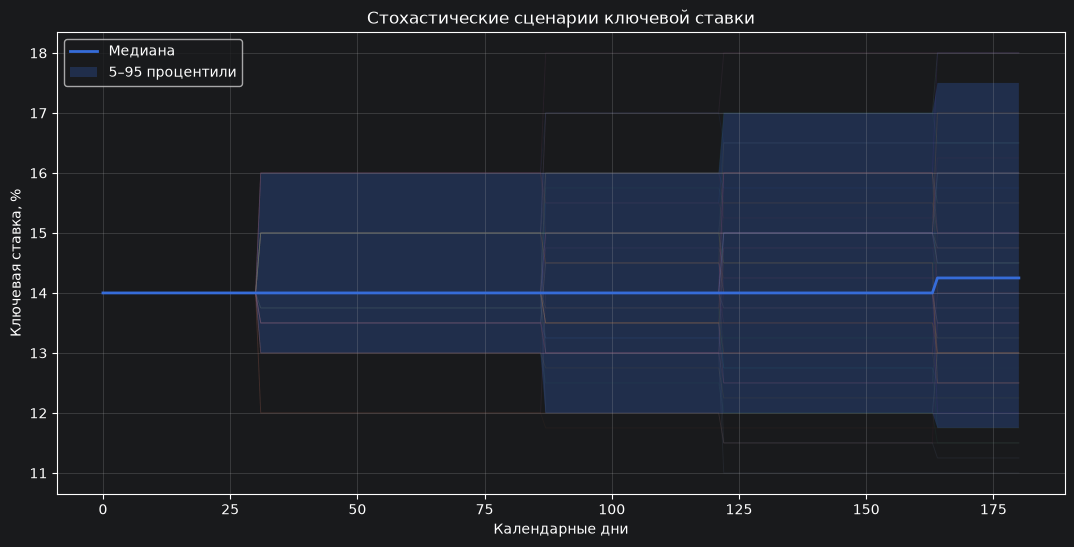

In [17]:
plt.figure(figsize=(13, 6))

plt.plot(
    np.arange(max_days + 1),
    key_paths[:, :100],
    alpha=0.08,
    linewidth=0.7
)

q05, q50, q95 = np.quantile(
    key_paths,
    [0.05, 0.50, 0.95],
    axis=1
)

plt.plot(q50, linewidth=2, label="Медиана")
plt.fill_between(
    np.arange(max_days + 1),
    q05, q95,
    alpha=0.25,
    label="5–95 процентили"
)

plt.xlabel("Календарные дни")
plt.ylabel("Ключевая ставка, %")
plt.title("Стохастические сценарии ключевой ставки")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

In [18]:
nominal = 1000.0
margin_pp = 2.0

results = []

for method, spread_sim in simulations.items():

    # Случайная RUONIA:
    # ключевая ставка + спред
    ruonia_sim = (
        key_paths[1:181] + spread_sim[:180]
    )

    # Купон 1
    coupon_1 = (
        nominal
        * (ruonia_sim[:90].mean(axis=0) + margin_pp)
        / 100
        * 90 / 365
    )

    # Купон 2
    coupon_2 = (
        nominal
        * (ruonia_sim[90:180].mean(axis=0) + margin_pp)
        / 100
        * 90 / 365
    )

    # Реинвестирование первого купона
    factor = np.prod(
        1 + key_paths[91:181] / (100 * 365),
        axis=0
    )

    total = coupon_1 * factor + coupon_2

    results.append({
        "Метод": method,
        "Купон 1, ₽": coupon_1.mean(),
        "Купон 2, ₽": coupon_2.mean(),
        "Итого, ₽": total.mean(),
        "Std, ₽": total.std(ddof=1),
        "5%, ₽": np.quantile(total, 0.05),
        "95%, ₽": np.quantile(total, 0.95),
    })

stochastic_coupon_results = pd.DataFrame(results)

display(stochastic_coupon_results.round(4))

,Метод,"Купон 1, ₽","Купон 2, ₽","Итого, ₽","Std, ₽","5%, ₽","95%, ₽"
0,Gaussian,39.1707,39.6313,80.2092,4.6117,73.3319,88.4078
1,IID Bootstrap,39.1717,39.6280,80.2070,4.6150,73.4009,88.4880
2,Block 10,39.1772,39.6335,80.2182,4.6091,73.4054,88.4371


In [19]:
periods = {
    "2023–2024": ("2023-01-01", "2024-12-31"),
    "2025–2026": ("2025-01-01", "2026-12-31"),
    "2023–2026": ("2023-01-01", "2026-12-31"),
}

rows = []

for name, (start, end) in periods.items():

    sample = decisions.loc[
        decisions["date"].between(start, end),
        "delta_pp"
    ]

    rows.append({
        "Период": name,
        "Решений": len(sample),
        "P(повышения)": (sample > 0).mean(),
        "P(сохранения)": (sample == 0).mean(),
        "P(снижения)": (sample < 0).mean(),
        "Среднее ΔКС": sample.mean(),
        "Std ΔКС": sample.std(),
    })

regime_comparison = pd.DataFrame(rows)

display(regime_comparison.round(4))

,Период,Решений,P(повышения),P(сохранения),P(снижения),Среднее ΔКС,Std ΔКС
0,2023–2024,16,0.4375,0.5625,0.0000,0.6250,0.8062
1,2025–2026,15,0.0000,0.3333,0.6667,-0.4667,0.5417
2,2023–2026,31,0.2258,0.4516,0.3226,0.0968,0.8772
